# Appendix: Ablation Studies

Three sensitivity sweeps for the main H1 results. All scenarios use S1 (full participation, all TCT rounds).
- **Alpha sweep**: RDP order α ∈ {5, 10, 20, 32, 50, 75, 100, 128}
- **Population distribution**: Beta shape varied
- **Delta sweep**: δ∞ ∈ {1e-3, 1e-2, 1e-1}

In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import matplotlib.pyplot as plt

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 13,
    'axes.labelsize': 13, 'axes.titlesize': 14,
    'legend.fontsize': 11, 'xtick.labelsize': 11,
    'ytick.labelsize': 11, 'lines.linewidth': 2.0,
    'axes.spines.top': False, 'axes.spines.right': False,
})

TCT_Z_COLOR = '#2166ac'
TCT_S_COLOR = '#1a9641'
IDP_COLOR   = '#d6604d'

In [2]:
# ── Base parameters ───────────────────────────────────────────────────────────
EPSILON        = 0.01
DELTA_BASE     = 1e-2
ALPHA_BASE     = 75.0
N_USERS        = 10000
N_ROUNDS       = 1500
EPS_RDP_BUDGET = 1.0
TARGET_HIT     = 0.02
SEED           = 42
N_PILOT        = 3000

q = q_from_epsilon(EPSILON)
print(f'epsilon={EPSILON}, q={q:.4f}')

# ── Helpers ───────────────────────────────────────────────────────────────────
def calibrate_T(pop_cfg, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    counts = np.empty(N_PILOT)
    for i in range(N_PILOT):
        parts = list(pop.active_users)
        if not parts:
            counts[i] = rng.laplace(0.0, 1.0 / EPSILON)
            continue
        cnt, _ = compute_round_conversions(parts, rng)
        counts[i] = cnt + rng.laplace(0.0, 1.0 / EPSILON)
    T = float(np.quantile(counts, 1.0 - TARGET_HIT))
    return T, float(np.mean(counts >= T))


def run_sim(accountant_factory, pop_cfg, T, rho,
            p_participate=1.0, interleave_ratio=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    frac, avg_budget = [], []
    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if parts:
            is_tct = (interleave_ratio == 0.0 or rng.random() >= interleave_ratio)
            if is_tct:
                cnt, contribs = compute_round_conversions(parts, rng)
                is_top, _ = laplace_threshold_query(cnt, T, EPSILON, rng)
                for i, u in enumerate(parts):
                    e, d = acc.charge(user=u, is_top=is_top,
                                      contributed=contribs[i], round_num=r)
                    u.epsilon_spent += e
                    u.delta_spent   += d
            else:
                for u in parts:
                    u.epsilon_spent += rho
        pop.drop_depleted()
        eps_dist = pop.epsilon_remaining_distribution()
        frac.append(pop.active_fraction)
        avg_budget.append(float(np.mean(eps_dist)) if eps_dist else 0.0)
    return frac, avg_budget


def half_life(frac):
    for r, f in enumerate(frac):
        if f <= 0.5: return r
    return len(frac)


def pad(c, n):
    fill = c[-1] if c else 0.0
    return list(c) + [fill] * (n - len(c))


def hl_label(hl, n):
    return f'\u2265{hl}' if hl >= n - 1 else str(hl)


def plot_panel(ax, zf, sf, idpf, hl_z, hl_s, hl_i, leg_loc, tag):
    n = max(len(zf), len(sf), len(idpf)) + 1
    rnds = list(range(n))
    za = pad(zf, n); sa = pad(sf, n); ia = pad(idpf, n)
    ax.plot(rnds, ia, color=IDP_COLOR,   lw=2.0, linestyle=':',
            label=f'Std. RDP\n(HL={hl_i})')
    ax.plot(rnds, za, color=TCT_Z_COLOR, lw=2.0,
            label=f'A-TCT Zeta-2\n(HL={hl_label(hl_z, n)})')
    ax.plot(rnds, sa, color=TCT_S_COLOR, lw=2.0, linestyle='--',
            label=f'A-TCT Stitched\n(HL={hl_label(hl_s, n)})')
    ax.fill_between(rnds, ia, za, alpha=0.10, color=TCT_Z_COLOR)
    ax.axhline(0.5, color='#aaa', lw=0.75, linestyle=':', zorder=0)
    if hl_i < n - 2:
        ax.axvline(hl_i, color=IDP_COLOR, lw=0.9, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round', fontsize=16)
    ax.set_xlim(0, n - 1); ax.set_ylim(-0.02, 1.08)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.legend(loc=leg_loc, fontsize=12, frameon=True, framealpha=0.88,
              borderpad=0.45, labelspacing=0.55, handlelength=2.2)
    ax.text(0.5, 1.02, tag, transform=ax.transAxes,
            fontsize=13, ha='center', va='bottom', style='italic',
            bbox=dict(boxstyle='round,pad=0.25', fc='white', alpha=0.88, ec='#cccccc', lw=0.8))


def plot_panel_budget(ax, zb, sb, ib, leg_loc, tag):
    n = max(len(zb), len(sb), len(ib)) + 1
    rnds = list(range(n))
    zb_ = pad(zb, n); sb_ = pad(sb, n); ib_ = pad(ib, n)
    ax.plot(rnds, ib_, color=IDP_COLOR,   lw=2.0, linestyle=':', label='Std. RDP')
    ax.plot(rnds, zb_, color=TCT_Z_COLOR, lw=2.0,               label='A-TCT Zeta-2')
    ax.plot(rnds, sb_, color=TCT_S_COLOR, lw=2.0, linestyle='--', label='A-TCT Stitched')
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round', fontsize=16)
    ax.set_xlim(0, n - 1); ax.set_ylim(bottom=0)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.legend(loc=leg_loc, fontsize=12, frameon=True, framealpha=0.88,
              borderpad=0.45, labelspacing=0.55, handlelength=2.2)
    ax.text(0.5, 1.02, tag, transform=ax.transAxes,
            fontsize=13, ha='center', va='bottom', style='italic',
            bbox=dict(boxstyle='round,pad=0.25', fc='white', alpha=0.88, ec='#cccccc', lw=0.8))

epsilon=0.01, q=0.4975


## 1. Alpha Sweep (S1)


In [3]:
# ── Alpha sweep: S1 (full participation, no interleaving) ─────────────────────
ALPHA_SWEEP = [5, 10, 20, 32, 50, 75, 100, 128]

pop_cfg_a = PopulationConfig(n_users=N_USERS, alpha=0.5, beta=2.0,
                              epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0)
T_a, hr_a = calibrate_T(pop_cfg_a)
print(f'T={T_a:.2f}, emp hit rate={hr_a:.3f}')
print()

alpha_results = {}
for a in ALPHA_SWEEP:
    rho = a * EPSILON**2 / 2.0
    acc_z = AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=a, schedule='zeta2')
    acc_s = AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=a, schedule='stitched')
    k1z = acc_z.budget_cost(acc_z.compositions(1))
    k1s = acc_s.budget_cost(acc_s.compositions(1))
    print(f'alpha={a:3d}  rho={rho:.6f}  K1*rho: Zeta-2={k1z:.4f} ({100*k1z:.1f}%)  '
          f'Stitched={k1s:.4f} ({100*k1s:.1f}%)')
    fz, fz_b = run_sim(lambda a=a: AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=a,
                        schedule='zeta2', independent=True),
                       pop_cfg_a, T_a, rho, p_participate=1.0, interleave_ratio=0.0)
    fs, fs_b = run_sim(lambda a=a: AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=a,
                        schedule='stitched', independent=True),
                       pop_cfg_a, T_a, rho, p_participate=1.0, interleave_ratio=0.0)
    fi, fi_b = run_sim(lambda rho=rho: StandardDPAccountant(rho),
                       pop_cfg_a, T_a, rho, p_participate=1.0, interleave_ratio=0.0)
    hl_z = half_life(fz); hl_s = half_life(fs); hl_i = half_life(fi)
    alpha_results[a] = dict(fz=fz, fs=fs, fi=fi,
                             fz_b=fz_b, fs_b=fs_b, fi_b=fi_b,
                             hl_z=hl_z, hl_s=hl_s, hl_i=hl_i, rho=rho)
    print(f'  Zeta-2 hl={hl_z}, Stitched hl={hl_s}, IDP hl={hl_i}')
    print()

T=2290.40, emp hit rate=0.020

alpha=  5  rho=0.000250  K1*rho: Zeta-2=0.0061 (0.6%)  Stitched=0.0210 (2.1%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=1500

alpha= 10  rho=0.000500  K1*rho: Zeta-2=0.0122 (1.2%)  Stitched=0.0420 (4.2%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=1500

alpha= 20  rho=0.001000  K1*rho: Zeta-2=0.0244 (2.4%)  Stitched=0.0841 (8.4%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=999

alpha= 32  rho=0.001600  K1*rho: Zeta-2=0.0390 (3.9%)  Stitched=0.1345 (13.5%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=624

alpha= 50  rho=0.002500  K1*rho: Zeta-2=0.0609 (6.1%)  Stitched=0.2102 (21.0%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=400

alpha= 75  rho=0.003750  K1*rho: Zeta-2=0.0914 (9.1%)  Stitched=0.3152 (31.5%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266

alpha=100  rho=0.005000  K1*rho: Zeta-2=0.1218 (12.2%)  Stitched=0.4203 (42.0%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=199

alpha=128  rho=0.006400  K1*rho: Zeta-2=0.1560 (15.6%)  Stitched=0.5380 (53.8%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=156



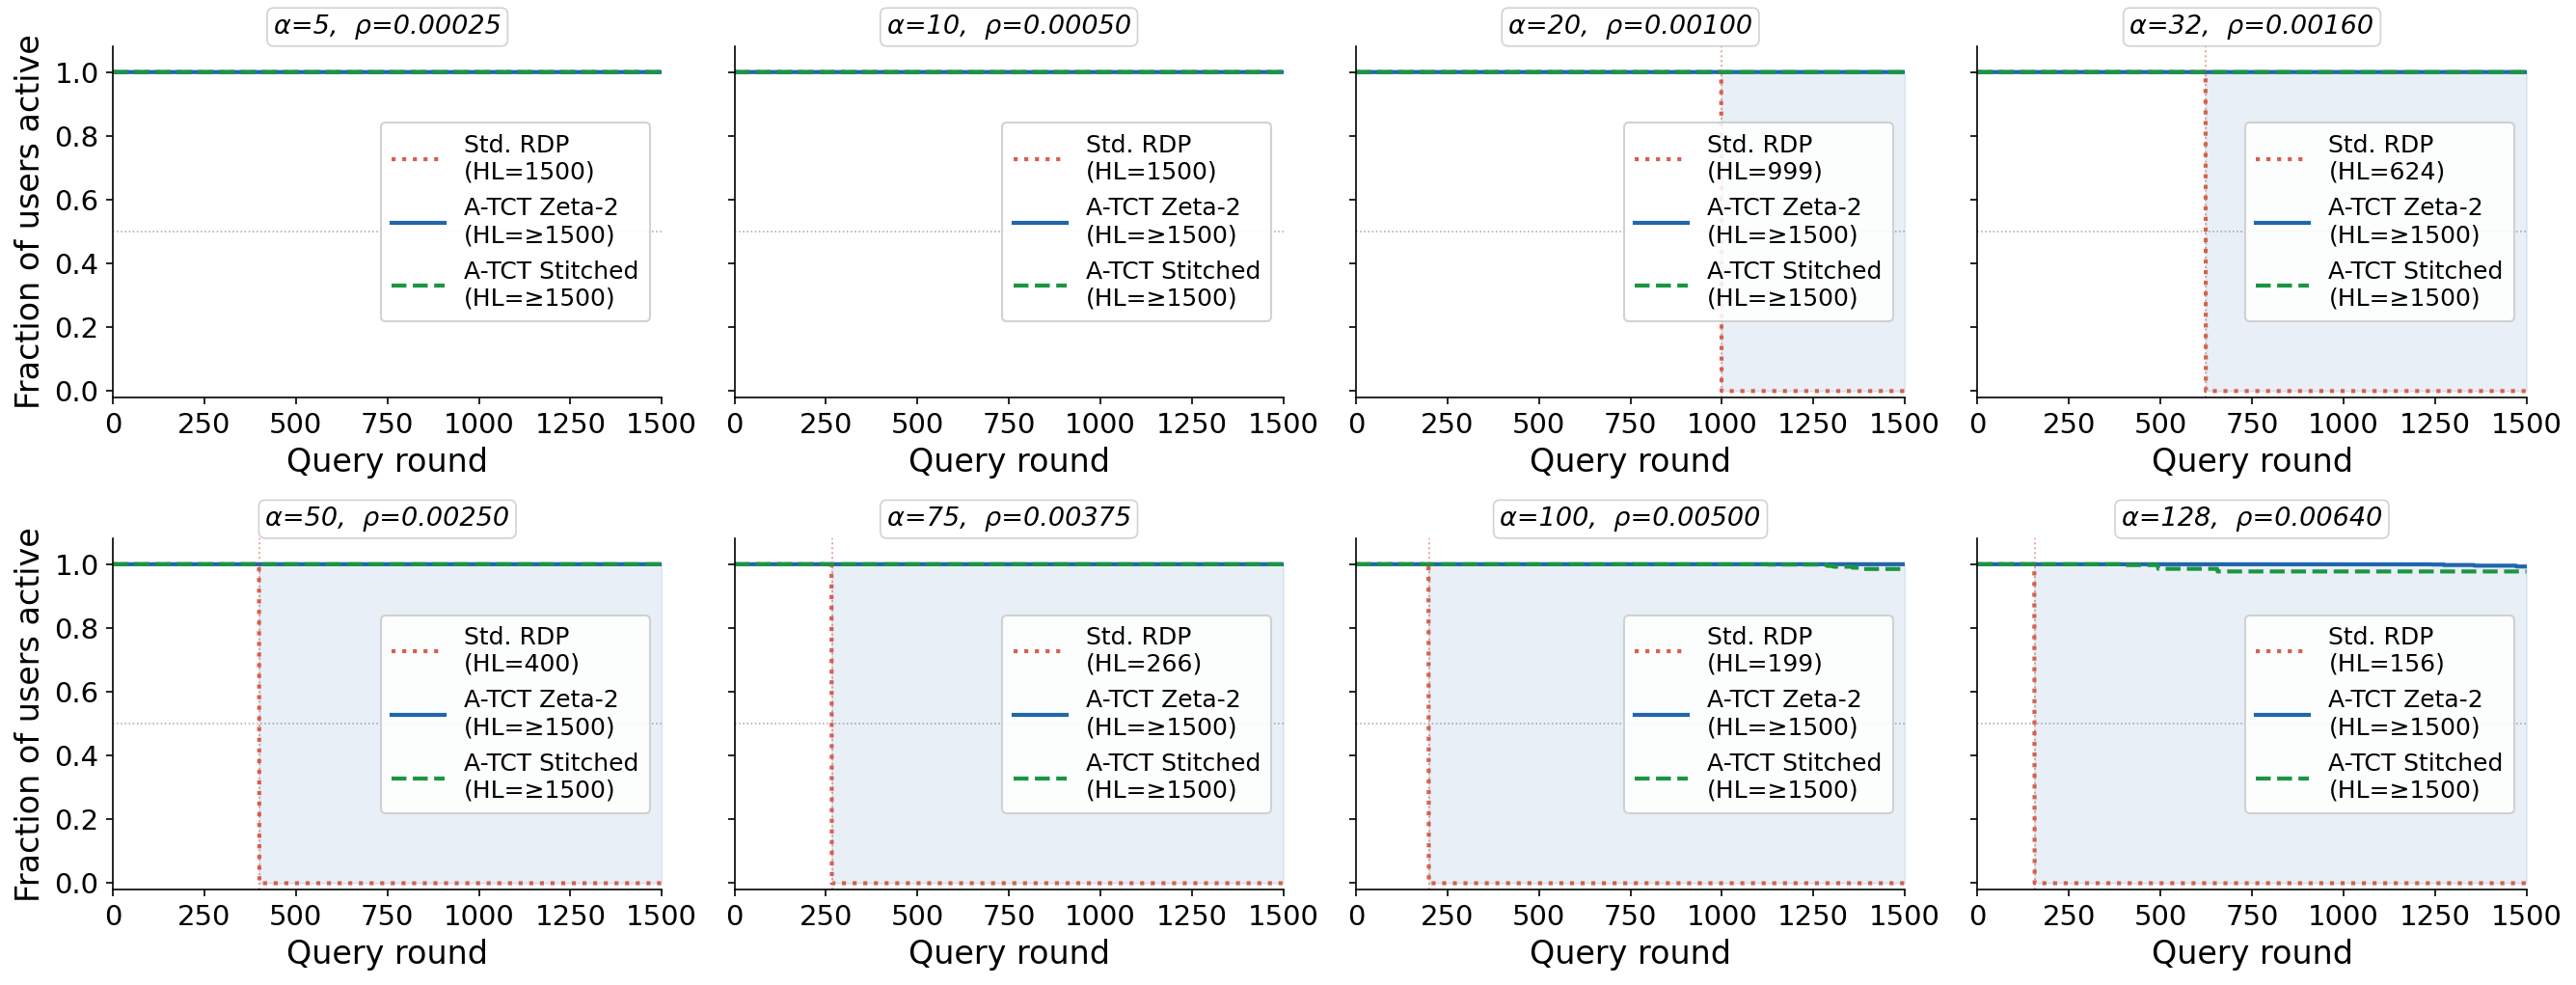

Saved figures/ablation_alpha_sweep.png


In [4]:
# ── Alpha sweep: Retention figure (2×4 grid) ──────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7.0), sharey=True)
axes_flat = axes.flatten()

for ax, a in zip(axes_flat, ALPHA_SWEEP):
    r = alpha_results[a]
    tag = f'\u03b1={a},  \u03c1={r["rho"]:.5f}'
    plot_panel(ax, r['fz'], r['fs'], r['fi'], r['hl_z'], r['hl_s'], r['hl_i'],
               'center right', tag)

for ax in axes[:, 0]:
    ax.set_ylabel('Fraction of users active', fontsize=16)

plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_alpha_sweep.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_alpha_sweep.png')

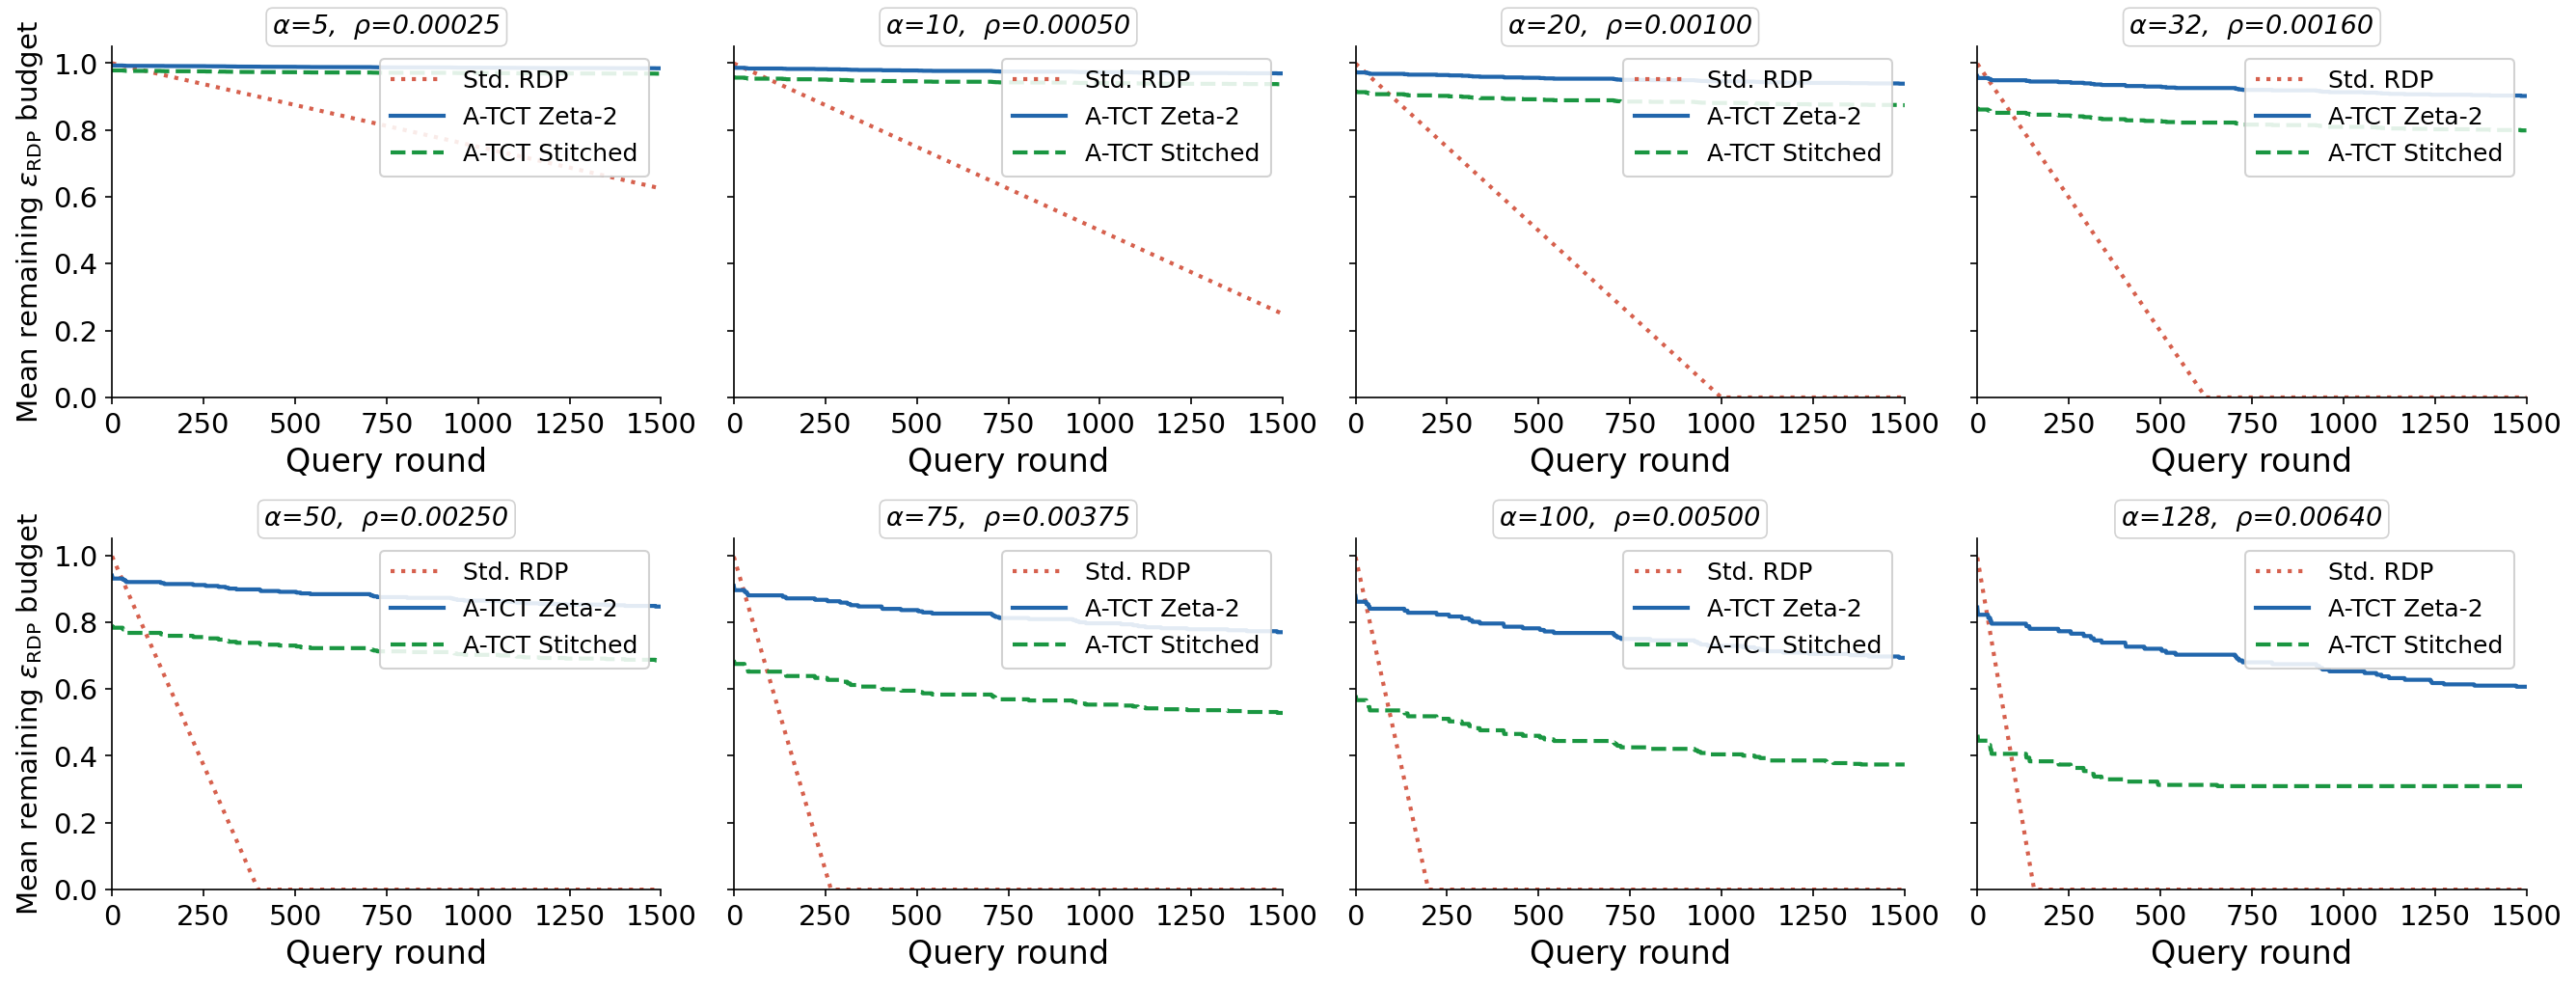

Saved figures/ablation_alpha_sweep_budget.png


In [5]:
# ── Alpha sweep: Budget figure (2×4 grid) ─────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7.0), sharey=True)
axes_flat = axes.flatten()

for ax, a in zip(axes_flat, ALPHA_SWEEP):
    r = alpha_results[a]
    tag = f'\u03b1={a},  \u03c1={r["rho"]:.5f}'
    plot_panel_budget(ax, r['fz_b'], r['fs_b'], r['fi_b'], 'upper right', tag)

for ax in axes[:, 0]:
    ax.set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget', fontsize=14)

plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_alpha_sweep_budget.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_alpha_sweep_budget.png')

## 2. Population Distribution Sweep (S1)


In [6]:
# ── Population distribution sweep: S1 ────────────────────────────────────────
rho_base = ALPHA_BASE * EPSILON**2 / 2.0
POP_PARAMS = [
    (0.5, 2.0, 'Beta(0.5, 2.0)\nmean=0.20, heavy tail'),
    (1.0, 1.0, 'Beta(1.0, 1.0)\nmean=0.50, uniform'),
    (0.5, 0.5, 'Beta(0.5, 0.5)\nmean=0.50, bimodal'),
]

pop_results = {}
for ap, bp, label in POP_PARAMS:
    cfg = PopulationConfig(n_users=N_USERS, alpha=ap, beta=bp,
                           epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0)
    T, hr = calibrate_T(cfg)
    mean_rate = ap / (ap + bp)
    print(f'Beta({ap},{bp})  mean={mean_rate:.2f}  T={T:.2f}  hit rate={hr:.3f}')
    fz, fz_b = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=ALPHA_BASE,
                        schedule='zeta2', independent=True),
                       cfg, T, rho_base, p_participate=1.0, interleave_ratio=0.0)
    fs, fs_b = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA_BASE, alpha_rdp=ALPHA_BASE,
                        schedule='stitched', independent=True),
                       cfg, T, rho_base, p_participate=1.0, interleave_ratio=0.0)
    fi, fi_b = run_sim(lambda: StandardDPAccountant(rho_base),
                       cfg, T, rho_base, p_participate=1.0, interleave_ratio=0.0)
    hl_z = half_life(fz); hl_s = half_life(fs); hl_i = half_life(fi)
    pop_results[label] = dict(fz=fz, fs=fs, fi=fi,
                               fz_b=fz_b, fs_b=fs_b, fi_b=fi_b,
                               hl_z=hl_z, hl_s=hl_s, hl_i=hl_i)
    print(f'  Zeta-2 hl={hl_z}, Stitched hl={hl_s}, IDP hl={hl_i}')
    print()

Beta(0.5,2.0)  mean=0.20  T=2290.40  hit rate=0.020


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266



Beta(1.0,1.0)  mean=0.50  T=5335.84  hit rate=0.020


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266



Beta(0.5,0.5)  mean=0.50  T=5331.69  hit rate=0.020


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266



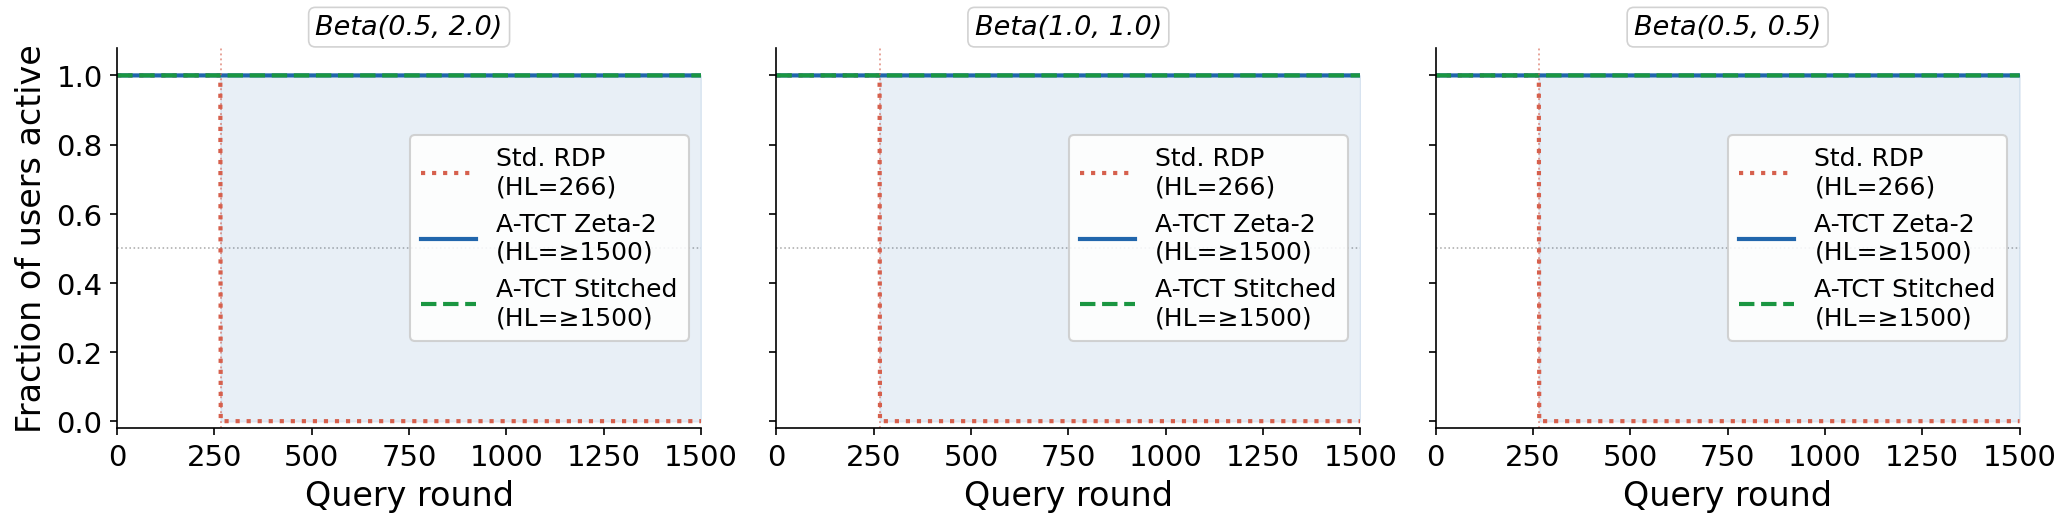

Saved figures/ablation_pop_distribution.png


In [7]:
# ── Population distribution: Retention figure ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, (ap, bp, label) in zip(axes, POP_PARAMS):
    r = pop_results[label]
    tag = f'Beta({ap}, {bp})'
    plot_panel(ax, r['fz'], r['fs'], r['fi'], r['hl_z'], r['hl_s'], r['hl_i'],
               'center right', tag)

axes[0].set_ylabel('Fraction of users active', fontsize=16)
plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_pop_distribution.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_pop_distribution.png')

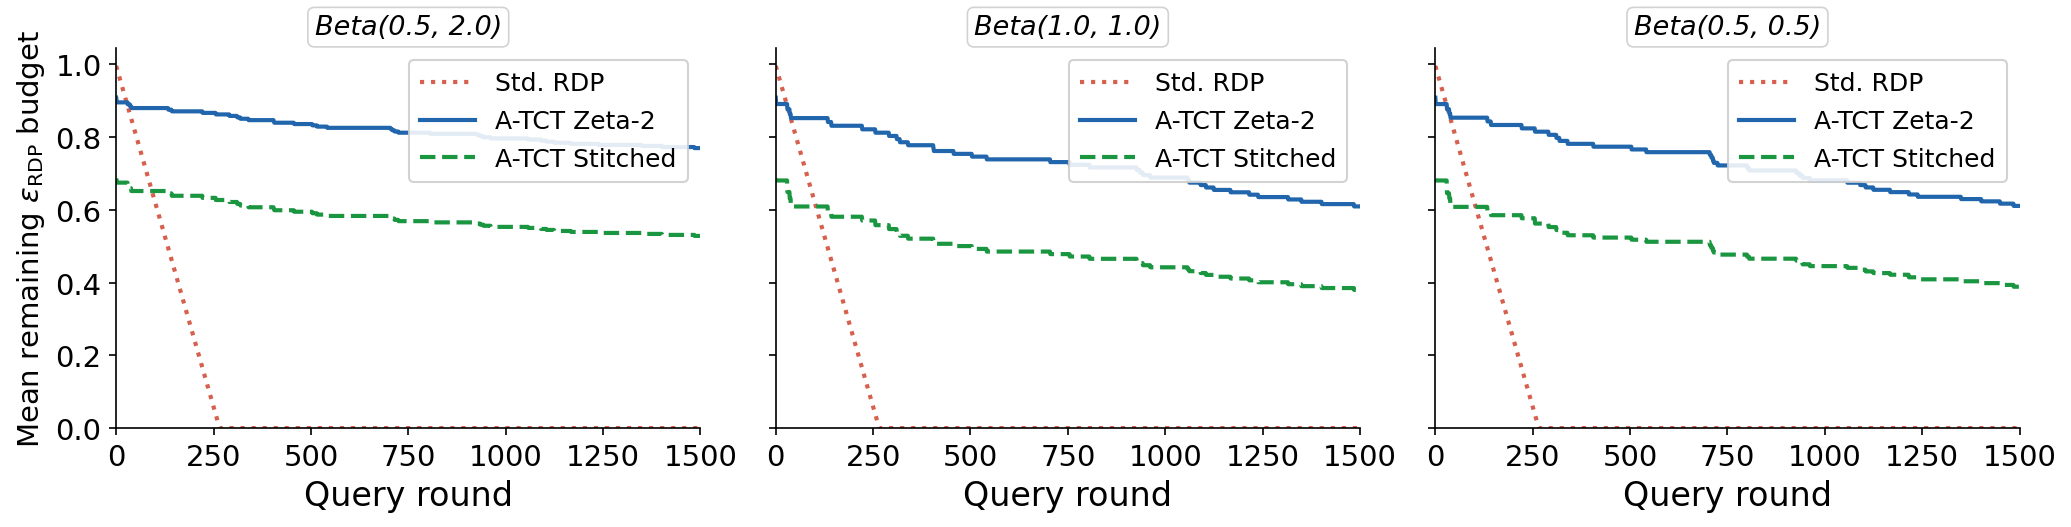

Saved figures/ablation_pop_distribution_budget.png


In [8]:
# ── Population distribution: Budget figure ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, (ap, bp, label) in zip(axes, POP_PARAMS):
    r = pop_results[label]
    tag = f'Beta({ap}, {bp})'
    plot_panel_budget(ax, r['fz_b'], r['fs_b'], r['fi_b'], 'upper right', tag)

axes[0].set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget', fontsize=14)
plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_pop_distribution_budget.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_pop_distribution_budget.png')

## 3. Delta Sweep (S2)


In [9]:
# ── Delta sweep: S1 (full participation, no interleaving) ────────────────────
DELTA_VALS = [1e-3, 1e-2, 1e-1]
rho_d = ALPHA_BASE * EPSILON**2 / 2.0

pop_cfg_d = PopulationConfig(n_users=N_USERS, alpha=0.5, beta=2.0,
                              epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0)
T_d, hr_d = calibrate_T(pop_cfg_d)
print(f'T={T_d:.2f}, emp hit rate={hr_d:.3f}')
print()

delta_results = {}
for d in DELTA_VALS:
    acc_z = AdaptiveTCTAccountant(EPSILON, d, alpha_rdp=ALPHA_BASE, schedule='zeta2')
    acc_s = AdaptiveTCTAccountant(EPSILON, d, alpha_rdp=ALPHA_BASE, schedule='stitched')
    k1z = acc_z.budget_cost(acc_z.compositions(1))
    k1s = acc_s.budget_cost(acc_s.compositions(1))
    print(f'delta={d:.0e}  K1*rho: Zeta-2={k1z:.4f} ({100*k1z:.1f}%)  '
          f'Stitched={k1s:.4f} ({100*k1s:.1f}%)')
    fz, fz_b = run_sim(lambda d=d: AdaptiveTCTAccountant(EPSILON, d, alpha_rdp=ALPHA_BASE,
                        schedule='zeta2', independent=True),
                       pop_cfg_d, T_d, rho_d, p_participate=1.0, interleave_ratio=0.0)
    fs, fs_b = run_sim(lambda d=d: AdaptiveTCTAccountant(EPSILON, d, alpha_rdp=ALPHA_BASE,
                        schedule='stitched', independent=True),
                       pop_cfg_d, T_d, rho_d, p_participate=1.0, interleave_ratio=0.0)
    fi, fi_b = run_sim(lambda: StandardDPAccountant(rho_d),
                       pop_cfg_d, T_d, rho_d, p_participate=1.0, interleave_ratio=0.0)
    hl_z = half_life(fz); hl_s = half_life(fs); hl_i = half_life(fi)
    delta_results[d] = dict(fz=fz, fs=fs, fi=fi,
                             fz_b=fz_b, fs_b=fs_b, fi_b=fi_b,
                             hl_z=hl_z, hl_s=hl_s, hl_i=hl_i)
    print(f'  Zeta-2 hl={hl_z}, Stitched hl={hl_s}, IDP hl={hl_i}')
    print()

T=2290.40, emp hit rate=0.020

delta=1e-03  K1*rho: Zeta-2=0.1263 (12.6%)  Stitched=0.4541 (45.4%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266

delta=1e-02  K1*rho: Zeta-2=0.0914 (9.1%)  Stitched=0.3152 (31.5%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266

delta=1e-01  K1*rho: Zeta-2=0.0563 (5.6%)  Stitched=0.1764 (17.6%)


  Zeta-2 hl=1500, Stitched hl=1500, IDP hl=266



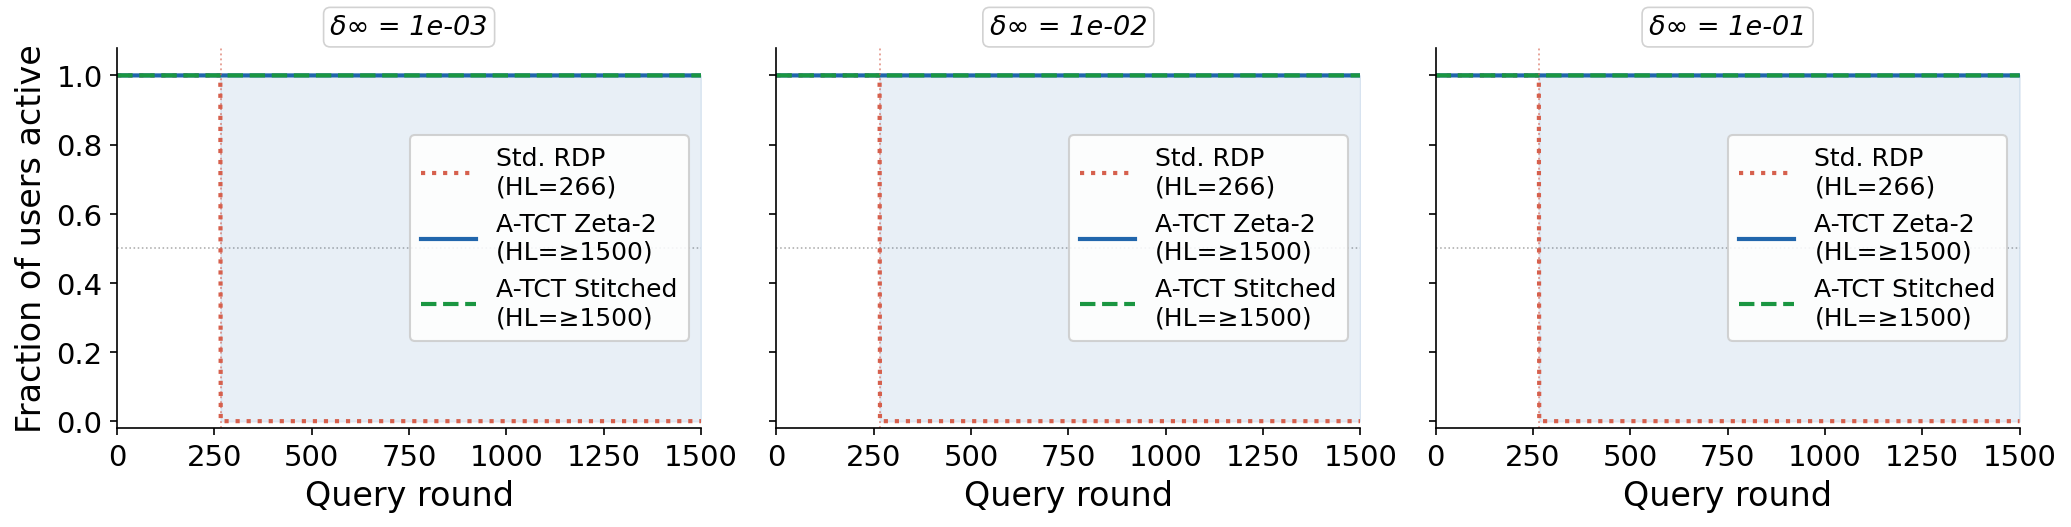

Saved figures/ablation_delta_sweep.png


In [10]:
# ── Delta sweep: Retention figure ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, d in zip(axes, DELTA_VALS):
    r = delta_results[d]
    tag = f'\u03b4\u221e = {d:.0e}'
    plot_panel(ax, r['fz'], r['fs'], r['fi'], r['hl_z'], r['hl_s'], r['hl_i'],
               'center right', tag)

axes[0].set_ylabel('Fraction of users active', fontsize=16)
plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_delta_sweep.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_delta_sweep.png')

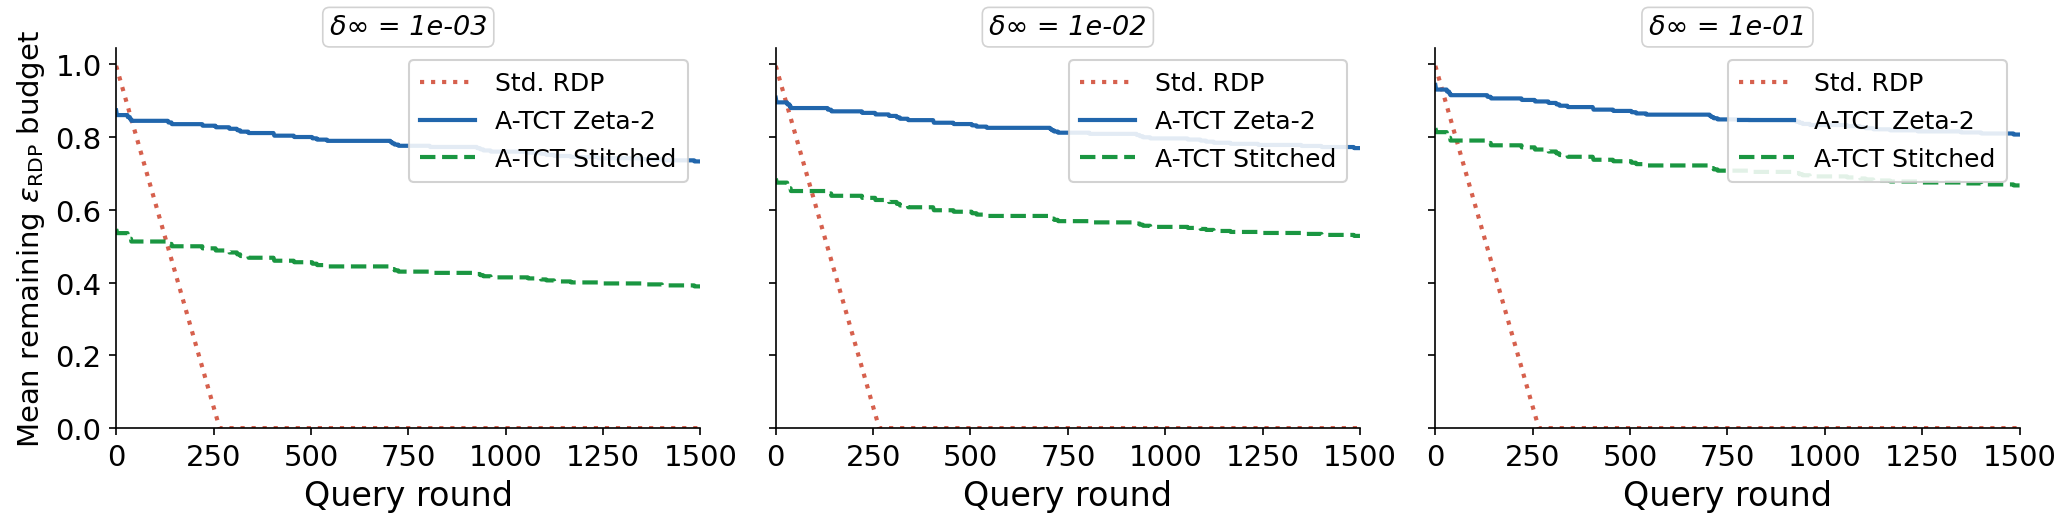

Saved figures/ablation_delta_sweep_budget.png


In [11]:
# ── Delta sweep: Budget figure ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, d in zip(axes, DELTA_VALS):
    r = delta_results[d]
    tag = f'\u03b4\u221e = {d:.0e}'
    plot_panel_budget(ax, r['fz_b'], r['fs_b'], r['fi_b'], 'upper right', tag)

axes[0].set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget', fontsize=14)
plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.savefig('../figures/ablation_delta_sweep_budget.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/ablation_delta_sweep_budget.png')